# Basic `optimex` Example

This notebook demonstrates the core `optimex` workflow using dummy processes — no external databases required.

We set up a simple system with **two products**, each producible via **two alternative routes**, and let `optimex` find the climate-optimal transition pathway.

The pipeline follows four steps:

1. **Database setup** — biosphere, background, and foreground in Brightway
2. **LCA processing** — extract time-explicit LCA data
3. **Optimization** — find the climate-optimal deployment schedule
4. **Post-processing** — visualize results


## 1. Database Setup

We create a standalone Brightway project with:

- A **biosphere** database (CO2, CH4, land occupation)
- Three **background databases** at different points in time (2020, 2035, 2050) representing evolving supply chains
- A **foreground** database with our decision-relevant processes


In [1]:
from datetime import datetime
import numpy as np
import bw2data as bd
from bw_temporalis import TemporalDistribution, easy_timedelta_distribution
import sys
from loguru import logger

# Show only warnings from optimex to keep the output short
logger.remove()
logger.add(sys.stderr, level="WARNING")

bd.projects.set_current("optimex_basic_example")

### Biosphere

Elementary flows that processes can emit or consume. When using ecoinvent, this is already available.


In [2]:
biosphere_data = {
    ("biosphere3", "CO2"): {
        "type": bd.labels.biosphere_node_default,
        "name": "carbon dioxide",
        "CAS number": "000124-38-9",
    },
    ("biosphere3", "CH4"): {
        "type": bd.labels.biosphere_node_default,
        "name": "methane, fossil",
        "CAS number": "000074-82-8",
    },
    ("biosphere3", "land_occupation"): {
        "type": bd.labels.biosphere_node_default,
        "name": "land occupation",
    },
}
bd.Database("biosphere3").write(biosphere_data)

16:29:21+0100 [info     ] Vacuuming database            


### Characterization Methods

Maps elementary flows to impact scores. With ecoinvent, standard methods (IPCC, ReCiPe, ...) are pre-loaded.


In [3]:
bd.Method(("GWP", "example")).write(
    [
        (("biosphere3", "CO2"), 1),
        (("biosphere3", "CH4"), 27),
    ]
)

bd.Method(("land use", "example")).write(
    [
        (("biosphere3", "land_occupation"), 1),
        (("biosphere3", "CH4"), 27),
    ]
)

### Background Databases

Background processes supply inputs to the foreground but are not decision variables. To model technological evolution, we provide **multiple snapshots** at different years. `optimex` interpolates between them.

Each database needs `representative_time` metadata so `optimex` knows which year it represents. In practice, tools like [premise](https://github.com/polca/premise) generate these from IAM scenarios.


In [4]:
# Background 2020
db_2020_data = {
    ("db_2020", "I1"): {
        "name": "node I1",
        "location": "somewhere",
        "type": bd.labels.chimaera_node_default,
        "reference product": "I1",
        "exchanges": [
            {
                "amount": 1,
                "type": bd.labels.production_edge_default,
                "input": ("db_2020", "I1"),
            },
            {
                "amount": 3000,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "CO2"),
            },
        ],
    },
    ("db_2020", "I2"): {
        "name": "node I2",
        "location": "somewhere",
        "type": bd.labels.chimaera_node_default,
        "reference product": "I2",
        "exchanges": [
            {
                "amount": 1,
                "type": bd.labels.production_edge_default,
                "input": ("db_2020", "I2"),
            },
            {
                "amount": 5,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "CH4"),
            },
        ],
    },
    ("db_2020", "I3"): {
        "name": "node I3",
        "location": "somewhere",
        "type": bd.labels.chimaera_node_default,
        "reference product": "I3",
        "exchanges": [
            {
                "amount": 1,
                "type": bd.labels.production_edge_default,
                "input": ("db_2020", "I3"),
            },
            {
                "amount": 3,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "CH4"),
            },
            {
                "amount": 10,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "land_occupation"),
            },
        ],
    },
}
bg_2020 = bd.Database("db_2020")
bg_2020.write(db_2020_data)
bg_2020.metadata["representative_time"] = datetime(2020, 1, 1).isoformat()
bg_2020.register()

# Background 2035 — lower emissions reflecting technological progress
db_2035_data = {
    ("db_2035", "I1"): {
        "name": "node I1",
        "location": "somewhere",
        "type": bd.labels.chimaera_node_default,
        "reference product": "I1",
        "exchanges": [
            {
                "amount": 1,
                "type": bd.labels.production_edge_default,
                "input": ("db_2035", "I1"),
            },
            {
                "amount": 2500,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "CO2"),
            },
        ],
    },
    ("db_2035", "I2"): {
        "name": "node I2",
        "location": "somewhere",
        "type": bd.labels.chimaera_node_default,
        "reference product": "I2",
        "exchanges": [
            {
                "amount": 1,
                "type": bd.labels.production_edge_default,
                "input": ("db_2035", "I2"),
            },
            {
                "amount": 2,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "CH4"),
            },
        ],
    },
    ("db_2035", "I3"): {
        "name": "node I3",
        "location": "somewhere",
        "type": bd.labels.chimaera_node_default,
        "reference product": "I3",
        "exchanges": [
            {
                "amount": 1,
                "type": bd.labels.production_edge_default,
                "input": ("db_2035", "I3"),
            },
            {
                "amount": 2,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "CH4"),
            },
            {
                "amount": 7,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "land_occupation"),
            },
        ],
    },
}
bg_2035 = bd.Database("db_2035")
bg_2035.write(db_2035_data)
bg_2035.metadata["representative_time"] = datetime(2035, 1, 1).isoformat()
bg_2035.register()

# Background 2050 — further improvements
db_2050_data = {
    ("db_2050", "I1"): {
        "name": "node I1",
        "location": "somewhere",
        "type": bd.labels.chimaera_node_default,
        "reference product": "I1",
        "exchanges": [
            {
                "amount": 1,
                "type": bd.labels.production_edge_default,
                "input": ("db_2050", "I1"),
            },
            {
                "amount": 2200,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "CO2"),
            },
        ],
    },
    ("db_2050", "I2"): {
        "name": "node I2",
        "location": "somewhere",
        "type": bd.labels.chimaera_node_default,
        "reference product": "I2",
        "exchanges": [
            {
                "amount": 1,
                "type": bd.labels.production_edge_default,
                "input": ("db_2050", "I2"),
            },
            {
                "amount": 1,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "CH4"),
            },
        ],
    },
    ("db_2050", "I3"): {
        "name": "node I3",
        "location": "somewhere",
        "type": bd.labels.chimaera_node_default,
        "reference product": "I3",
        "exchanges": [
            {
                "amount": 1,
                "type": bd.labels.production_edge_default,
                "input": ("db_2050", "I3"),
            },
            {
                "amount": 1,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "CH4"),
            },
            {
                "amount": 7,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "land_occupation"),
            },
        ],
    },
}
bg_2050 = bd.Database("db_2050")
bg_2050.write(db_2050_data)
bg_2050.metadata["representative_time"] = datetime(2050, 1, 1).isoformat()
bg_2050.register()

16:29:21+0100 [warning  ] Not able to determine geocollections for all datasets. This database is not ready for regionalization.


16:29:21+0100 [info     ] Vacuuming database            


16:29:21+0100 [warning  ] Not able to determine geocollections for all datasets. This database is not ready for regionalization.


16:29:21+0100 [info     ] Vacuuming database            


16:29:21+0100 [warning  ] Not able to determine geocollections for all datasets. This database is not ready for regionalization.


16:29:21+0100 [info     ] Vacuuming database            


### Foreground Database

The foreground contains the **decision-relevant processes** whose installation and operation timing `optimex` optimizes.

Key `optimex`-specific attributes on processes and exchanges:

- **`operation_time_limits`**: tuple `(start, end)` defining the operation phase within a process lifetime
- **`temporal_distribution`**: when each exchange occurs relative to installation (using `TemporalDistribution`)
- **`operation: True`**: marks exchanges that scale with operational level (production, operational emissions)

All processes buy their construction inputs from the background in their installation year (process time 0) and operate from the following year on (process time 1), so `operation_time_limits` start at 1.

Our system has two products, each with two production routes:

- **Product 1**: Route 1 (6-year operation, uses I1+I3, captures CO2 during operation) vs. Route 2 (11-year operation, uses I2+I3, captures CO2 during operation)
- **Product 2**: Route 1 (15-year operation, needs Product 1, uses I3, emits CO2) vs. Route 2 (7-year operation, needs Product 1, uses I2, captures CO2 during operation)


In [5]:
if "foreground" in bd.databases:
    del bd.databases["foreground"]
foreground = bd.Database("foreground")
foreground.register()

In [6]:
foreground_data = {
    # --- Product 1 and its two production routes ---
    ("foreground", "Product 1"): {
        "name": "Product 1",
        "unit": "kg",
        "type": bd.labels.product_node_default,
    },
    ("foreground", "P1R1"): {
        "name": "Product 1 production, Route 1",
        "location": "somewhere",
        "type": bd.labels.process_node_default,
        "operation_time_limits": (1, 6),
        "exchanges": [
            {
                "amount": 1,
                "type": bd.labels.production_edge_default,
                "input": ("foreground", "Product 1"),
                "temporal_distribution": easy_timedelta_distribution(
                    start=1, end=6, steps=6, resolution="Y", kind="uniform"
                ),
                "operation": True,
            },
            {
                "amount": 27.5,
                "type": bd.labels.consumption_edge_default,
                "input": ("db_2020", "I1"),
                "temporal_distribution": TemporalDistribution(
                    date=np.array([0], dtype="timedelta64[Y]"), amount=np.array([1])
                ),
            },
            {
                "amount": 35,
                "type": bd.labels.consumption_edge_default,
                "input": ("db_2020", "I3"),
                "temporal_distribution": TemporalDistribution(
                    date=np.array([0], dtype="timedelta64[Y]"), amount=np.array([1])
                ),
            },
            {
                "amount": -20,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "CO2"),
                "temporal_distribution": easy_timedelta_distribution(
                    start=1, end=6, steps=6, resolution="Y", kind="uniform"
                ),
                "operation": True,
            },
        ],
    },
    ("foreground", "P1R2"): {
        "name": "Product 1 production, Route 2",
        "location": "somewhere",
        "type": bd.labels.process_node_default,
        "operation_time_limits": (1, 11),
        "exchanges": [
            {
                "amount": 1,
                "type": bd.labels.production_edge_default,
                "input": ("foreground", "Product 1"),
                "temporal_distribution": easy_timedelta_distribution(
                    start=1, end=11, steps=11, resolution="Y", kind="uniform"
                ),
                "operation": True,
            },
            {
                "amount": 10,
                "type": bd.labels.consumption_edge_default,
                "input": ("db_2020", "I2"),
                "temporal_distribution": TemporalDistribution(
                    date=np.array([0], dtype="timedelta64[Y]"), amount=np.array([1])
                ),
            },
            {
                "amount": 5,
                "type": bd.labels.consumption_edge_default,
                "input": ("db_2020", "I3"),
                "temporal_distribution": TemporalDistribution(
                    date=np.array([0], dtype="timedelta64[Y]"), amount=np.array([1])
                ),
            },
            {
                "amount": -20,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "CO2"),
                "temporal_distribution": easy_timedelta_distribution(
                    start=1, end=11, steps=11, resolution="Y", kind="uniform"
                ),
                "operation": True,
            },
        ],
    },
    # --- Product 2 and its two production routes ---
    ("foreground", "Product 2"): {
        "name": "Product 2",
        "unit": "kg",
        "type": bd.labels.product_node_default,
    },
    ("foreground", "P2R1"): {
        "name": "Product 2 production, Route 1",
        "location": "somewhere",
        "type": bd.labels.process_node_default,
        "operation_time_limits": (1, 15),
        "exchanges": [
            {
                "amount": 1,
                "type": bd.labels.production_edge_default,
                "input": ("foreground", "Product 2"),
                "temporal_distribution": easy_timedelta_distribution(
                    start=1, end=15, steps=15, resolution="Y", kind="uniform"
                ),
                "operation": True,
            },
            {
                "amount": 1,
                "type": bd.labels.consumption_edge_default,
                "input": ("foreground", "Product 1"),
                "temporal_distribution": easy_timedelta_distribution(
                    start=1, end=15, steps=15, resolution="Y", kind="uniform"
                ),
                "operation": True,
            },
            {
                "amount": 18.5,
                "type": bd.labels.consumption_edge_default,
                "input": ("db_2020", "I3"),
                "temporal_distribution": TemporalDistribution(
                    date=np.array([0], dtype="timedelta64[Y]"), amount=np.array([1])
                ),
            },
            {
                "amount": 3,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "CO2"),
                "temporal_distribution": easy_timedelta_distribution(
                    start=1, end=15, steps=15, resolution="Y", kind="uniform"
                ),
                "operation": True,
            },
        ],
    },
    ("foreground", "P2R2"): {
        "name": "Product 2 production, Route 2",
        "location": "somewhere",
        "type": bd.labels.process_node_default,
        "operation_time_limits": (1, 7),
        "exchanges": [
            {
                "amount": 1,
                "type": bd.labels.production_edge_default,
                "input": ("foreground", "Product 2"),
                "temporal_distribution": easy_timedelta_distribution(
                    start=1, end=7, steps=7, resolution="Y", kind="uniform"
                ),
                "operation": True,
            },
            {
                "amount": 1,
                "type": bd.labels.consumption_edge_default,
                "input": ("foreground", "Product 1"),
                "temporal_distribution": easy_timedelta_distribution(
                    start=1, end=7, steps=7, resolution="Y", kind="uniform"
                ),
                "operation": True,
            },
            {
                "amount": 15.5,
                "type": bd.labels.consumption_edge_default,
                "input": ("db_2020", "I2"),
                "temporal_distribution": TemporalDistribution(
                    date=np.array([0], dtype="timedelta64[Y]"), amount=np.array([1])
                ),
            },
            {
                "amount": -10,
                "type": bd.labels.biosphere_edge_default,
                "input": ("biosphere3", "CO2"),
                "temporal_distribution": easy_timedelta_distribution(
                    start=1, end=7, steps=7, resolution="Y", kind="uniform"
                ),
                "operation": True,
            },
        ],
    },
}

fg = bd.Database("foreground")
fg.write(foreground_data)
fg.register()

16:29:21+0100 [warning  ] Not able to determine geocollections for all datasets. This database is not ready for regionalization.


16:29:21+0100 [info     ] Vacuuming database            


### Demand

Define time-varying demand for Product 2 from 2025 to 2049. `optimex` will determine the optimal process mix to meet this demand each year.


In [7]:
years = range(2025, 2050)
rng = np.random.default_rng(42)

td_demand = TemporalDistribution(
    date=np.array(
        [datetime(year, 1, 1).isoformat() for year in years], dtype="datetime64[s]"
    ),
    amount=rng.random(len(years)) * 10,
)

functional_demand = {bd.get_node(database="foreground", name="Product 2"): td_demand}

## 2. LCA Processing

Configure the LCA: specify the demand, temporal settings, and characterization methods. The `LCADataProcessor` extracts all time-explicit LCA tensors needed for optimization.


In [8]:
from optimex import lca_processor

lca_config = lca_processor.LCAConfig(
    demand=functional_demand,
    temporal={
        "start_date": datetime(2020, 1, 1),
        "temporal_resolution": "year",
        "time_horizon": 100,
    },
    characterization_methods=[
        {
            "category_name": "climate_change",
            "brightway_method": ("GWP", "example"),
        },
    ],
)

lca_data_processor = lca_processor.LCADataProcessor(lca_config)

### Convert to Optimization Inputs

The `ModelInputManager` converts LCA data into `OptimizationModelInputs`. These can be saved/loaded to avoid re-running the LCA step.


In [9]:
from optimex import converter

manager = converter.ModelInputManager()
optimization_model_inputs = manager.parse_from_lca_processor(lca_data_processor)

# Optionally save/load:
# manager.save_inputs("model_inputs.json")
# optimization_model_inputs = manager.load_inputs("model_inputs.json")

## 3. Optimization

Create and solve the optimization model. The objective is to minimize total climate change impact over the system time horizon.


In [10]:
from optimex import optimizer

model = optimizer.create_model(
    optimization_model_inputs,
    name="basic_example",
    objective_category="climate_change",
)

In [11]:
m, obj, results = optimizer.solve_model(model, solver_name="glpk", tee=False)

## 4. Post-processing

Visualize the optimal transition pathway: installations, operations, production vs. demand, and environmental impacts.


In [12]:
from optimex import postprocessing

pp = postprocessing.PostProcessor(m, plot_config={"figsize": (8, 4)})

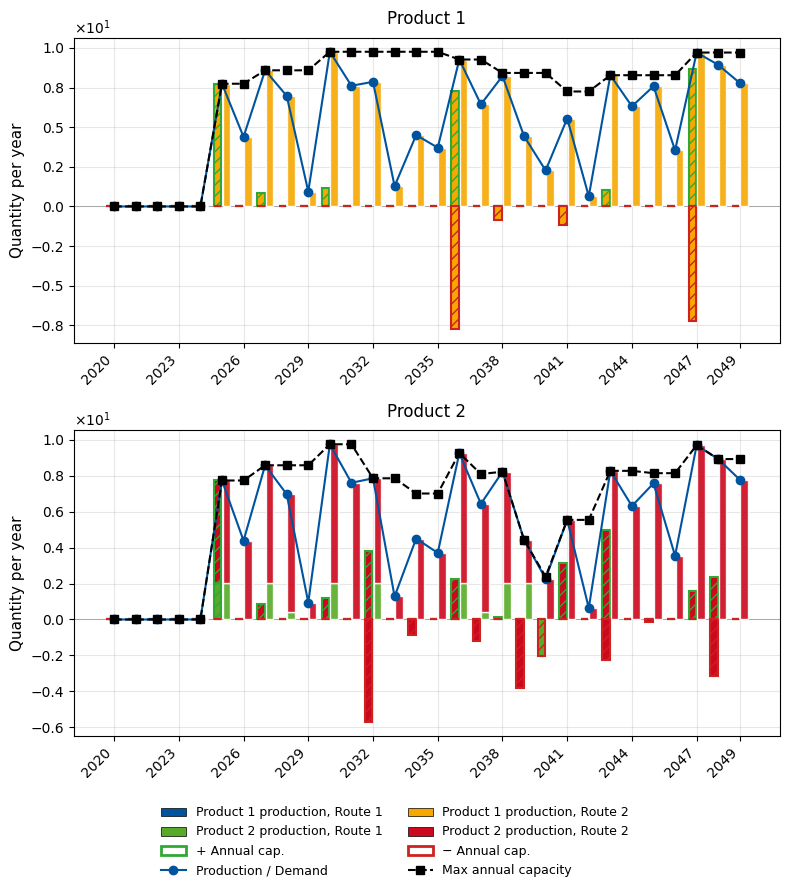

In [13]:
pp.plot_capacity_balance(detailed=True)

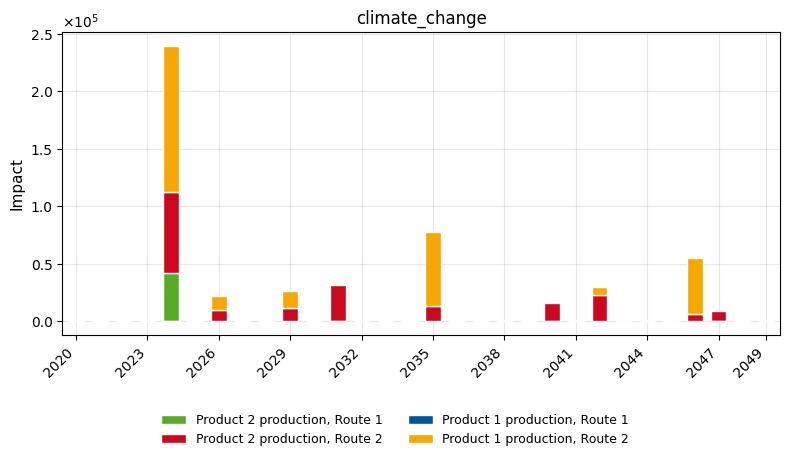

In [14]:
pp.plot_impacts()

### Dynamic inventory

The optimal pathway can also be characterized dynamically: the plot below shows
the radiative forcing caused by the pathway's emissions over time, computed with
[dynamic_characterization](https://dynamic-characterization.readthedocs.io).

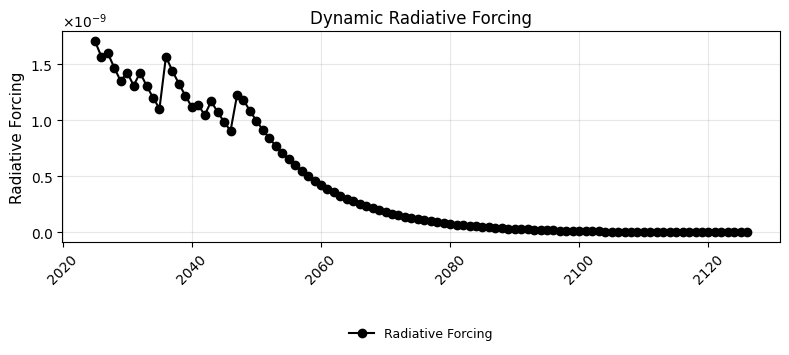

In [15]:
pp.plot_characterized_dynamic_inventory(
    base_lcia_method=("GWP", "example"), biosphere_database="biosphere3"
)

### Results as tables

All plots are built from DataFrames that the `PostProcessor` also returns
directly, e.g. for further analysis or export:

In [16]:
impacts = pp.get_impacts()
print(f"Total climate change impact: {obj:.4g} kg CO2-eq")
impacts["climate_change"].sum().rename("kg CO2-eq").round(1)

Total climate change impact: 5.017e+05 kg CO2-eq


Process
P2R1     42038.9
P1R1         0.0
P2R2    186058.1
P1R2    273626.1
Name: kg CO2-eq, dtype: float64

In [17]:
installations = pp.get_installation()
installations.loc[installations.abs().sum(axis=1) > 1e-6].round(2)

Process,P1R1,P1R2,P2R1,P2R2
Time,,,,
2024,0.0,85.14,30.76,39.82
2026,0.0,9.31,0.00,5.92
2029,0.0,12.87,0.00,8.19
2031,0.0,0.00,0.00,26.55
2035,0.0,79.76,0.00,15.77
2037,0.0,0.00,0.00,0.91
2040,0.0,0.00,0.00,22.14
2042,0.0,11.28,0.00,34.89
2046,0.0,95.50,0.00,10.93


### Interpretation

- **Installation ahead of demand:** units are installed in 2024, a year before
  demand starts, because each process operates from the year after its
  installation.
- **Product 1 from Route 2 only:** one unit of either route delivers 1 kg of
  Product 1 over its lifetime and captures 20 kg CO2 doing so, but Route 2 needs
  far less construction input per unit (10 I2 + 5 I3 instead of 27.5 I1 + 35 I3).
  Its installations come in waves 11 years apart (2024, 2035, 2046), as each
  cohort reaches the end of its 11-year operation window.
- **Product 2 mostly from Route 2:** Route 2 captures CO2 during operation, while
  Route 1 emits it; Route 1 is only installed once, at the start.
- **End of the horizon:** units installed in the last years only run for a few
  years within the modeled horizon, which ends in 2049. Their operation after
  2049 is not counted, see the pitfalls in
  [Minimizing Impacts](https://optimex.readthedocs.io/en/latest/content/minimizing_impacts/).

## Next steps

- [User Guide](https://optimex.readthedocs.io/en/latest/content/workflow/): the workflow step by step
- [Constraints](https://optimex.readthedocs.io/en/latest/content/constraints/): limit deployment, impacts, or resources
- [Basic cost example](basic_example_econ.ipynb): minimize costs under a climate budget
- [Methanol & pig iron case study](methanol_and_iron.ipynb): a realistic case with ecoinvent and premise